# Pittsburgh City Trees Data Analysis
## Project Overview
Myy notebook here analyzes the city tree data across Pittsburgh neighborhoods. This is to determine which areas hashas the highest volume and abundance of living city trees. Basically theThe guiding metric assumes that a higher total count of healthy trees correlates with a greener, healthier, and more aesthetically pleasing neighborhood for the people. The dataset is froms from the University of Pittsburgh WPRDC.

Dataset: [WPRDC City Trees Dataset](https://data.wprdc.org/dataset/city-trees/resource/1515a93c-73e3-4425-9b35-1cd11b2196da)

## Data Cleaning and Preparation
To ensure data integrity and accurate neighborhood collections:
* **Missing Values**: Rows that were lacking valid neighborhood entries were completely dropped.
* **Outliers**: Any ies hasDead or empty conditions were excluded from this data analysis.

Total rows before cleaning: 45709

Number of rows with missing neighborhoods: 259
Number of dead trees or trees with missing conditions removed: 6583
Total trees after cleaning: 38867

Top 10 Pittsburgh Neighborhoods by City Trees:
                Neighborhood  Tree_Count
0        Squirrel Hill South        4809
1              Highland Park        2686
2        Squirrel Hill North        1867
3           South Side Flats        1435
4                  Shadyside        1286
5               East Liberty        1220
6                 Bloomfield        1157
7               Point Breeze        1153
8  Central Business District         880
9                Perry North         873


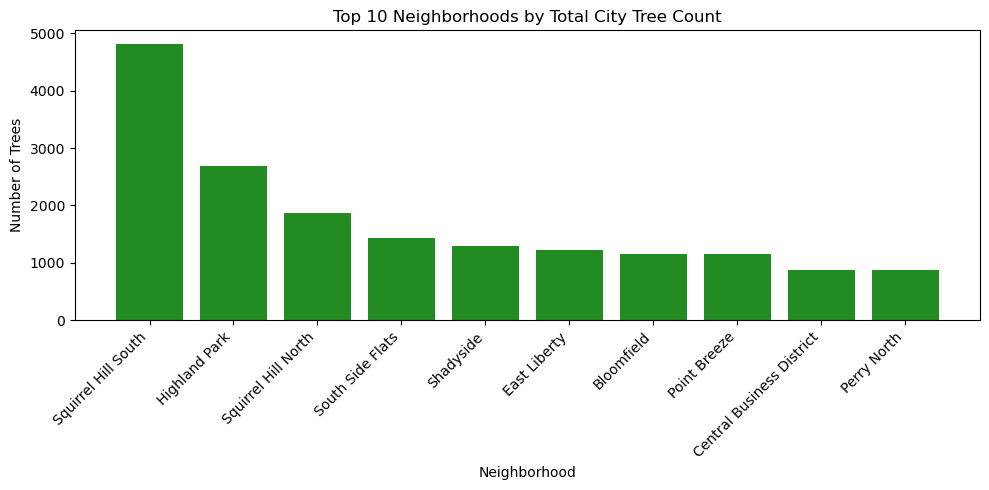

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset using the url
url = "https://data.wprdc.org/datastore/dump/1515a93c-73e3-4425-9b35-1cd11b2196da"
df = pd.read_csv(url, low_memory=False)

print(f"Total rows before cleaning: {len(df)}")

# Missing neighborhood outliers
missing_df = df[df['neighborhood'].isnull()]
print(f"\nNumber of rows with missing neighborhoods: {len(missing_df)}")
df = df.dropna(subset=['neighborhood'])

# Dead or empty condition outliers
dead_or_missing_condition = df[(df['condition'] == 'Dead') | (df['condition'].isnull())]
print(f"Number of dead trees or trees with missing conditions removed: {len(dead_or_missing_condition)}")
df = df[df['condition'].notnull() & (df['condition'] != 'Dead')]

df['neighborhood'] = df['neighborhood'].str.strip()

print(f"Total trees after cleaning: {len(df)}")

# Tree counts per neighborhood
tree_counts = df['neighborhood'].value_counts().reset_index()
tree_counts.columns = ['Neighborhood', 'Tree_Count']

print("\nTop 10 Pittsburgh Neighborhoods by City Trees:")
print(tree_counts.head(10))

# Plot top 10 neighborhoods with the most trees
plt.figure(figsize=(10, 5))
top_10 = tree_counts.head(10)
plt.bar(top_10['Neighborhood'], top_10['Tree_Count'], color='forestgreen')
plt.xlabel('Neighborhood')
plt.ylabel('Number of Trees')
plt.title('Top 10 Neighborhoods by Total City Tree Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


Bottom 10 Pittsburgh Neighborhoods with the Fewest City Trees:
         Neighborhood  Tree_Count
88         Glen Hazel           1
87        South Shore           1
86             Esplen           2
85  Arlington Heights           3
83  Northview Heights           4
84      East Carnegie           4
82          St. Clair          11
81         Mt. Oliver          13
80          Fairywood          18
79          Ridgemont          26


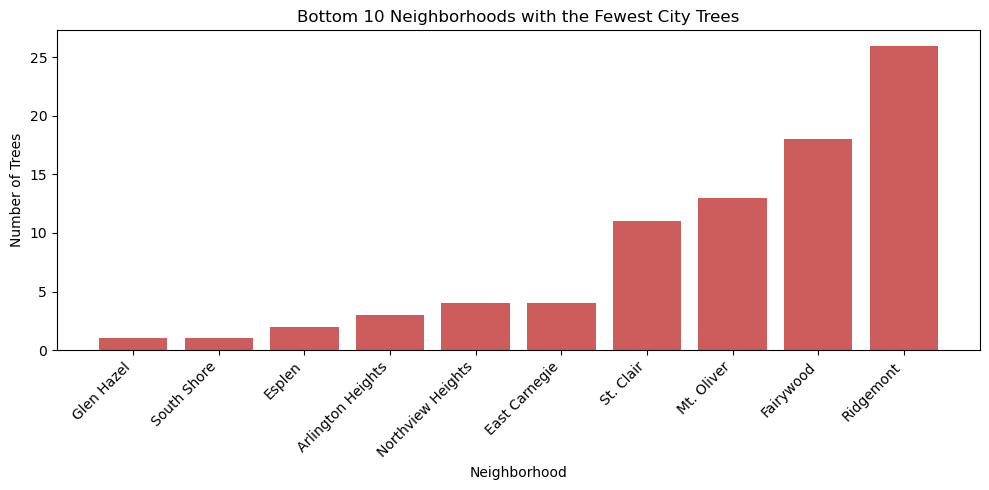

In [13]:
# Bottom 10 neighborhoods with the fewest trees
bottom_10 = tree_counts.tail(10).sort_values(by='Tree_Count', ascending=True)

print("\nBottom 10 Pittsburgh Neighborhoods with the Fewest City Trees:")
print(bottom_10)

# Plot 
plt.figure(figsize=(10, 5))
plt.bar(bottom_10['Neighborhood'], bottom_10['Tree_Count'], color='indianred')
plt.xlabel('Neighborhood')
plt.ylabel('Number of Trees')
plt.title('Bottom 10 Neighborhoods with the Fewest City Trees')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Conclusion
* **The Greenest Areas**: **Squirrel Hill South** leads the city by a pretty wide margin with 4809 living trees. This  that is top ranking if mostly driven from the  the amount ofneighborhood's massive public parks and well-established residential green spaces at that city.
* **The Least Vegetated Areas**: Neighborhoods with way more heavy industrial zoning, commercial density, or dense urban infrastructure register muchh morelowest overall tree counts in the city.
* **Insights**:  thethe By filtering out the outliers of there being dead trees and missing records, my analysis provides a way more clearer picture of the healthy urban canopy distribution across Pittbsurgh's neighborhoods.
* **Other Thoughts**: I did take in consideration of specific trees. Either if that is the height or width or benefits the tree provides. However, I did not want too many variables. Also with the species of the trees and setting one better than another is a bit subjective so I left that out and instead just did the total tree count since it was simplier to understand (of course the trees actually have to be alive to be considered). I don't think it would change that much about the data on whose on the top and whose on the bottom even if I added these data points. 